In [1]:
import pandas as pd
import matplotlib.pyplot as plt

container = pd.read_csv("../data/Container_Details_Cleaned.csv")

print("Dataset Shape:", container.shape)

display(container.head())

Dataset Shape: (100, 5)


,Container_ID,Container_Type,Capacity_KG,Sensor_ID,Refrigeration_Status
0,CONT001,Reefer_20ft,18000,SENS001,Operational
1,CONT002,Insulated_20ft,14000,SENS002,Operational
2,CONT003,Reefer_20ft,18000,SENS003,Operational
3,CONT004,Reefer_40ft,26000,SENS004,Operational
4,CONT005,Insulated_20ft,14000,SENS005,Operational


In [2]:
container_type_summary = container["Container_Type"].value_counts()

display(container_type_summary)

Container_Type
Reefer_20ft       38
Insulated_20ft    34
Reefer_40ft       28
Name: count, dtype: int64

In [3]:
refrigeration_summary = container["Refrigeration_Status"].value_counts()

display(refrigeration_summary)

Refrigeration_Status
Operational     95
Intermittent     5
Name: count, dtype: int64

In [4]:
capacity_summary = container["Capacity_KG"].describe()

display(capacity_summary.round(2))

count      100.00
mean     18880.00
std       4776.37
min      14000.00
25%      14000.00
50%      18000.00
75%      26000.00
max      26000.00
Name: Capacity_KG, dtype: float64

In [5]:
type_capacity = container.groupby("Container_Type").agg(
    Total_Containers=("Container_ID", "count"),
    Average_Capacity=("Capacity_KG", "mean"),
    Minimum_Capacity=("Capacity_KG", "min"),
    Maximum_Capacity=("Capacity_KG", "max")
)

display(type_capacity.round(2))

,Total_Containers,Average_Capacity,Minimum_Capacity,Maximum_Capacity
Container_Type,,,,
Insulated_20ft,34,14000.0,14000,14000
Reefer_20ft,38,18000.0,18000,18000
Reefer_40ft,28,26000.0,26000,26000


In [6]:
total_capacity = container["Capacity_KG"].sum()

print("Total Number of Containers:", len(container))
print("Total Storage Capacity:", total_capacity, "KG")
print("Average Capacity per Container:",
      round(container["Capacity_KG"].mean(), 2), "KG")

Total Number of Containers: 100
Total Storage Capacity: 1888000 KG
Average Capacity per Container: 18880.0 KG


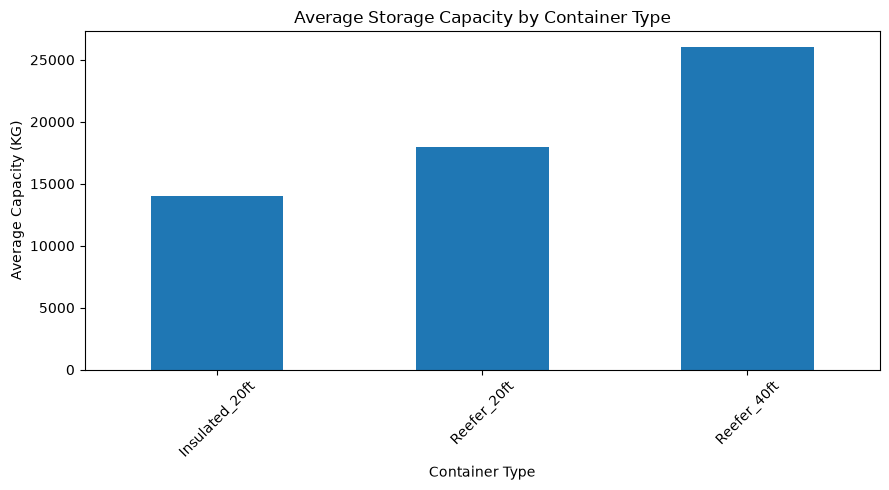

In [7]:
type_capacity["Average_Capacity"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Storage Capacity by Container Type")
plt.xlabel("Container Type")
plt.ylabel("Average Capacity (KG)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
refrigeration_by_type = pd.crosstab(
    container["Container_Type"],
    container["Refrigeration_Status"]
)

display(refrigeration_by_type)

Refrigeration_Status,Intermittent,Operational
Container_Type,,
Insulated_20ft,1,33
Reefer_20ft,3,35
Reefer_40ft,1,27


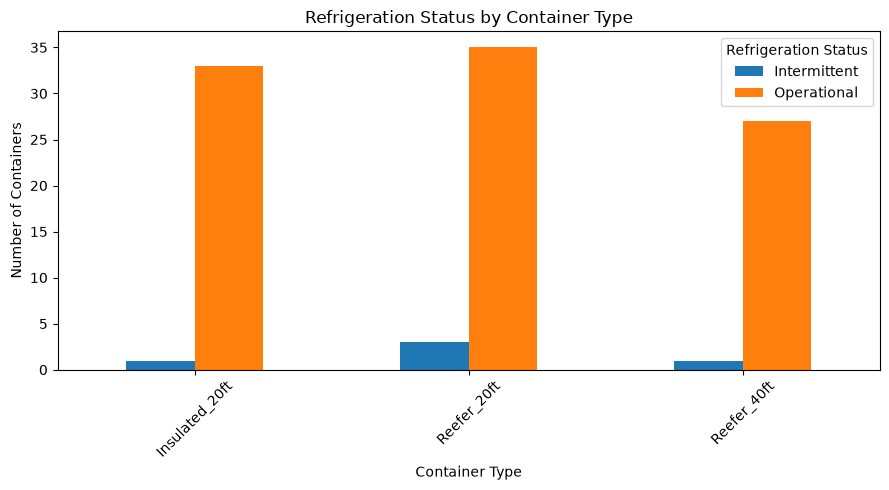

In [9]:
refrigeration_by_type.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Refrigeration Status by Container Type")
plt.xlabel("Container Type")
plt.ylabel("Number of Containers")
plt.xticks(rotation=45)
plt.legend(title="Refrigeration Status")
plt.tight_layout()
plt.show()

In [10]:
container.to_csv(
    "../outputs/container_analysis_data.csv",
    index=False
)

type_capacity.to_csv(
    "../outputs/container_capacity_summary.csv"
)

refrigeration_by_type.to_csv(
    "../outputs/container_refrigeration_summary.csv"
)

print("All container analysis files saved successfully!")

All container analysis files saved successfully!
